In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')

In [3]:
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [4]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Frame Index              10332 non-null  int64  
 1   FPS                      10332 non-null  float64
 2   Frame Duration (ms)      10332 non-null  float64
 3   Min Frame Duration (ms)  10332 non-null  float64
 4   Max Frame Duration (ms)  10332 non-null  float64
 5   Avg Frame Duration (ms)  10332 non-null  float64
 6   Std Dev (ms)             10332 non-null  float64
 7   Entropy Framerate        10332 non-null  float64
 8   MotionToPhotonLatency    10332 non-null  float64
 9   minMtpLatency            10332 non-null  float64
 10  maxMtpLatency            10332 non-null  float64
 11  avgMtpLatency            10332 non-null  float64
 12  StdDev mtpLatency        10332 non-null  float64
 13  mtpEntropy               10332 non-null  float64
 14  currentRotation.x     

In [5]:
Data = Data.iloc[:, 1:]
#Data = Data.iloc[:, 0:]
#Data = Data.iloc[:, 1:-14]
#Data = Data.iloc[:, 8:-1]

In [6]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [7]:
Data['Labels'] = Data['FPS'].apply(lambda x: 0 if x>=60 else 1)
#Data["Labels"] = Data["MotionToPhotonLatency"].apply(lambda x: 0 if x <= 20 else 1)

In [8]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,...,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,...,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71,0
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,...,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73,0
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,...,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75,0
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,...,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85,0
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,...,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,...,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87,1
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,...,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15,1
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,...,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37,1
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,...,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80,1


In [9]:
Data.shape

(10332, 21)

In [10]:
X = Data.drop('Labels', axis = 1)

In [11]:
y = Data['Labels']

In [12]:
feature_names = X.columns

In [13]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled , y, test_size=0.3, random_state=42)

In [15]:
# Create the Ridge regression model
model = Ridge(alpha=0.000433, random_state=42)

In [16]:
# Fit the model to the training data
model.fit(X_train, y_train)

Ridge(alpha=0.000433, random_state=42)

In [17]:
# Evaluate the model on the test set
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

In [18]:
print(f"Test set RMSE: {rmse:.4f}")

Test set RMSE: 0.1837


In [19]:
# Get the coefficients of the LASSO model
Coefficients = model.coef_

In [20]:
Ridge_coef = pd.DataFrame(Coefficients, index=feature_names, columns=["Coefficients"])

In [21]:
Ridge_coef

,Coefficients
FPS,-0.418331
Frame Duration (ms),-0.067795
Min Frame Duration (ms),-0.013329
Max Frame Duration (ms),-0.004263
Avg Frame Duration (ms),-0.217725
Std Dev (ms),0.011748
Entropy Framerate,0.018837
MotionToPhotonLatency,-0.001506
minMtpLatency,-0.034138
maxMtpLatency,0.026374


In [22]:
# Reset index to convert feature names to a column
Ridge_coef.reset_index(inplace=True)
Ridge_coef.rename(columns={'index': 'Feature'}, inplace=True)

In [23]:
# Sort the DataFrame by coefficient values (from highest to lowest)
Ridge_coef.sort_values(by='Coefficients', ascending=False, inplace=True)

In [24]:
# Print the sorted DataFrame
print("Sorted Elastic Net coefficients:")
print(Ridge_coef)

Sorted Elastic Net coefficients:
                    Feature  Coefficients
10            avgMtpLatency      0.254707
9             maxMtpLatency      0.026374
6         Entropy Framerate      0.018837
5              Std Dev (ms)      0.011748
18                      yaw      0.011642
13        currentRotation.x      0.008824
19                     roll      0.001043
11        StdDev mtpLatency     -0.000019
16        currentRotation.w     -0.000702
17                    pitch     -0.000987
7     MotionToPhotonLatency     -0.001506
3   Max Frame Duration (ms)     -0.004263
12               mtpEntropy     -0.011445
2   Min Frame Duration (ms)     -0.013329
15        currentRotation.z     -0.026630
8             minMtpLatency     -0.034138
14        currentRotation.y     -0.040764
1       Frame Duration (ms)     -0.067795
4   Avg Frame Duration (ms)     -0.217725
0                       FPS     -0.418331


In [25]:
Ridge_coef

,Feature,Coefficients
10,avgMtpLatency,0.254707
9,maxMtpLatency,0.026374
6,Entropy Framerate,0.018837
5,Std Dev (ms),0.011748
18,yaw,0.011642
13,currentRotation.x,0.008824
19,roll,0.001043
11,StdDev mtpLatency,-0.000019
16,currentRotation.w,-0.000702
17,pitch,-0.000987


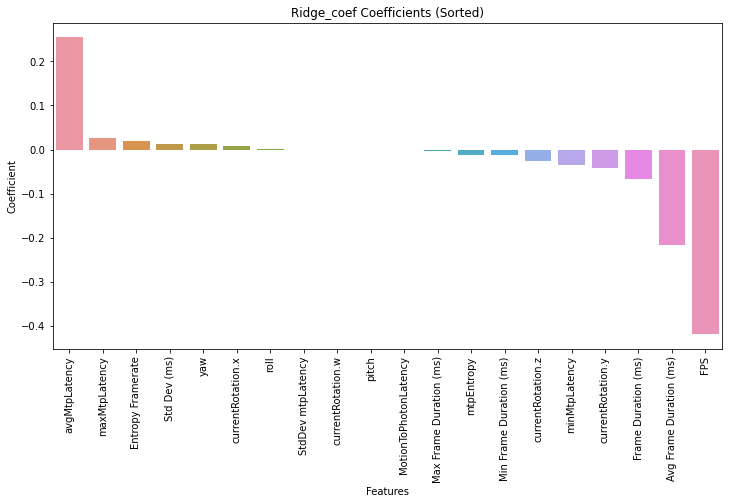

In [26]:
# Plot the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='Feature', y='Coefficients', data=Ridge_coef)
plt.xticks(rotation=90)
plt.title("Ridge_coef Coefficients (Sorted)")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.show()

In [27]:
# Identify selected features based on non-zero coefficients
selected_features = feature_names[np.nonzero(Coefficients)]
print("\nSelected features:")
print(selected_features)


Selected features:
Index(['FPS', 'Frame Duration (ms)', 'Min Frame Duration (ms)',
       'Max Frame Duration (ms)', 'Avg Frame Duration (ms)', 'Std Dev (ms)',
       'Entropy Framerate', 'MotionToPhotonLatency', 'minMtpLatency',
       'maxMtpLatency', 'avgMtpLatency', 'StdDev mtpLatency', 'mtpEntropy',
       'currentRotation.x', 'currentRotation.y', 'currentRotation.z',
       'currentRotation.w', 'pitch', 'yaw', 'roll'],
      dtype='object')


In [28]:
# Extract the non-zero coefficients
non_zero_coefficients = Coefficients[np.nonzero(Coefficients)]

In [29]:
# Create a DataFrame with the non-zero coefficients and corresponding feature names
Ridge_nonzerocoef = pd.DataFrame({"Feature": selected_features, "Coefficient": non_zero_coefficients})

In [30]:
Ridge_nonzerocoef 

,Feature,Coefficient
0,FPS,-0.418331
1,Frame Duration (ms),-0.067795
2,Min Frame Duration (ms),-0.013329
3,Max Frame Duration (ms),-0.004263
4,Avg Frame Duration (ms),-0.217725
5,Std Dev (ms),0.011748
6,Entropy Framerate,0.018837
7,MotionToPhotonLatency,-0.001506
8,minMtpLatency,-0.034138
9,maxMtpLatency,0.026374


In [31]:
Ridge_nonzerocoef.sort_values(by='Coefficient', ascending=False, inplace=True)

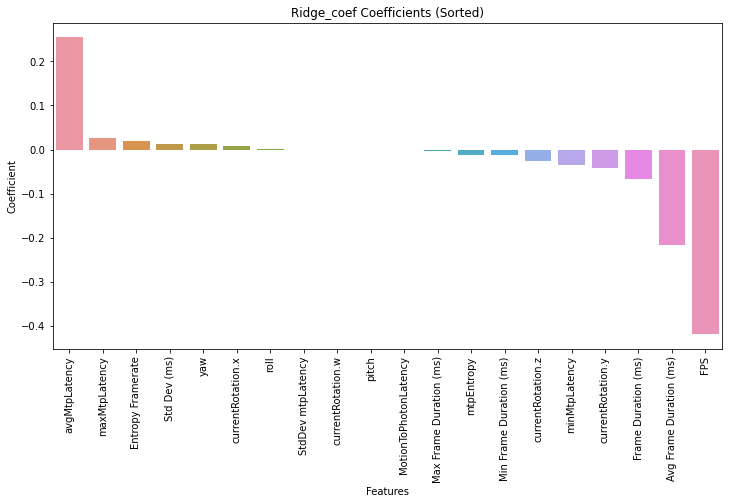

In [32]:
# Plot the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='Feature', y='Coefficient', data=Ridge_nonzerocoef)
plt.xticks(rotation=90)
plt.title("Ridge_coef Coefficients (Sorted)")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.show()